# TP RNN 2026 — Où sera l'avion dans 2 minutes ?

**ELISA Aerospace · 5e année · 3 h sur Google Colab · noté**

Un contrôleur aérien regarde son écran radar et doit savoir, à chaque instant, où seront les avions dans quelques minutes : c'est ce qui lui permet d'anticiper deux avions trop proches. Dans ce TP, vous allez apprendre à des **réseaux récurrents** à faire cette prédiction, sur **2 825 arrivées réelles** à Toulouse-Blagnac enregistrées en 2017.

Une trajectoire est une **séquence** : une suite de points dans le temps, comme une phrase est une suite de mots. Ce que vous avez vu dans le cours sur les RNN (la cellule, le gradient qui disparaît, le GRU et le LSTM, l'encodeur-décodeur) s'applique tel quel. Seule différence : ici, on peut **voir** ce que le réseau prédit, sur une carte. L'attention sera le sujet du TP Transformer.

## Règles du jeu

> **Vous pouvez utiliser une IA pour écrire ou corriger du code.** Le code n'est pas noté.
> Vous êtes notés **uniquement** sur les cellules **✍️ Réponse** : vos prédictions avant d'exécuter, vos observations sur *vos propres* figures, vos explications.
> Une réponse générique, qui pourrait avoir été écrite sans regarder la figure obtenue, vaut **zéro**.
> Une prédiction fausse mais assumée et expliquée vaut la note pleine.

| Marque | Sens |
|---|---|
| 🔧 **Fournie** | s'exécute telle quelle, lisez-la quand même |
| ✏️ **À compléter** | quelques lignes à écrire ; une cellule *Solution* repliée suit, à ouvrir après 5 min d'essai |
| ✍️ **Réponse Rn** | texte libre, **noté** |
| 🎁 **Bonus** | hors barème |

| Bloc | Question | Temps | Où |
|---|---|---|---|
| 0 | Mise en place | 10 min | séance |
| 1 | Les données : des vols réels | 30 min | séance |
| 2 | Ouvrir la cellule | 20 min | séance |
| 3 | Mémoire courte, mémoire longue | 30 min | séance |
| 4 | Générer la suite : l'encodeur-décodeur | 40 min | séance |
| S | Synthèse | 15 min | fin de séance ou maison |

### Comment lire ce notebook

Ce TP est aussi un cours. Chaque section suit le même schéma :
- une **figure** du cours ou une carte, et deux ou trois phrases qui rappellent la notion ;
- ⚠️ un piège à éviter, s'il y en a un ;
- 👀 **À regarder** : ce qu'il faut observer dans la sortie. Ce sont ces observations qui nourrissent vos Réponses ;
- un bloc replié **Détail du code et documentation**.

Notation des tenseurs : `(B, L, F)` = nombre de fenêtres dans le lot, nombre de pas de temps, nombre de variables par pas.

**Travail en binôme.** Chaque binôme a un numéro qui lui attribue **son propre vol** et sa propre longueur de mémoire (bloc 0).

<details><summary><b>Crédits des données</b></summary>
<ul>
<li>Trajectoires : X. Olive et L. Basora (2019), <i>Reference data sets for detection and identification of significant events in historical aircraft trajectory data</i>, figshare, <a href="https://doi.org/10.6084/m9.figshare.11406735">doi:10.6084/m9.figshare.11406735</a>, licence MIT. Données ADS-B collectées par <a href="https://opensky-network.org">The OpenSky Network</a> (M. Schäfer et al., 2014).</li>
<li>Fonds de carte : photographies aériennes et plan IGN, <a href="https://geoservices.ign.fr">Géoplateforme IGN</a>, Licence Ouverte Etalab 2.0.</li>
<li>Figures de cours : deck RNN du cours (Elisa Aerospace).</li>
</ul>
</details>

---
## Bloc 0 — Mise en place (10 min)

### 0.1 🔧 Bibliothèques et GPU

Activez le GPU **avant** de lancer la première cellule : menu *Exécution → Modifier le type d'exécution → T4 GPU*. Les réseaux de ce TP sont petits (quelques dizaines de milliers de poids) : sans GPU tout fonctionne, en plus lent, et chaque entraînement a des **poids de secours**.

> 👀 **À regarder** : la dernière ligne doit afficher `device : cuda`.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul><li><b>PyTorch</b> (<code>torch</code>) pour les tenseurs et les réseaux, <b>NumPy</b> pour les tableaux, <b>Matplotlib</b> pour les cartes et les courbes.</li><li><code>DEVICE</code> vaut <code>'cuda'</code> (GPU) ou <code>'cpu'</code>. Modèle et données doivent être au même endroit : <code>.to(DEVICE)</code>.</li></ul>
📖 <a href="https://docs.pytorch.org/tutorials/beginner/basics/intro.html">PyTorch, Learn the Basics</a> · <a href="https://matplotlib.org/stable/users/index.html">Matplotlib</a>
</details>

In [ ]:
import os, json, math, time, glob, zipfile, warnings
from pathlib import Path
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.path import Path as MPath
from matplotlib.markers import MarkerStyle
from matplotlib.transforms import Affine2D
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

import random
from IPython.display import Video, display
import pandas as pd
print('torch', torch.__version__, '| device :', DEVICE)
if DEVICE == 'cpu':
    print("⚠️ Pas de GPU : activez-le (Exécution → Modifier le type d'exécution) ou utilisez les poids de secours.")

### 0.2 🔧 Les données

La cellule **télécharge les données** depuis le dépôt GitHub du cours (un zip d'environ 12 Mo) et les décompresse. Si vous avez déjà le zip `TP_RNN_2026.zip`, déposez-le dans le panneau *Fichiers* de Colab : la cellule l'utilisera.

| Fichier | Contenu |
|---|---|
| `data/lfbo_arrivees.npz` | les 2 825 arrivées (304 000 points), le découpage train / val / test, les vols fil rouge |
| `data/fond_large.jpg`, `data/fond_zoom.jpg` | photographies aériennes IGN, déjà mises dans le repère du TP (km autour de l'aéroport) |
| `data/secours/` | poids des modèles déjà entraînés, si Colab est trop lent |

> ⚠️ **Attention** · L'espace de fichiers de Colab est effacé à la fin de la session. Au retour, relancez les cellules depuis le début.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul><li><code>find_data()</code> cherche un dossier <code>data/</code> déjà décompressé, sinon un zip déposé, sinon le télécharge (<code>urllib</code>).</li><li><code>charger_donnees()</code> lit le fichier <code>.npz</code> (plusieurs tableaux NumPy dans un même fichier) et range son contenu dans des variables globales : <code>POINTS</code>, <code>STARTS</code>, <code>PISTE</code>, <code>SPLIT</code>…</li><li><code>vol(v)</code> renvoie les points du vol numéro <code>v</code> : tous les vols sont mis bout à bout dans <code>POINTS</code>, et <code>STARTS[v]</code> donne l'indice de début du vol <code>v</code>.</li></ul>
📖 <a href="https://numpy.org/doc/stable/reference/generated/numpy.load.html">numpy.load</a> · <a href="https://docs.python.org/fr/3/library/pathlib.html">pathlib</a>
</details>

In [ ]:
DATA_URL = 'https://github.com/ArtificialIntelligenceModules/DeepLearning-2026-2027/releases/download/tp-rnn/TP_RNN_2026.zip'

def find_data():
    for d in ['data', 'TP_RNN_2026/data', '/content/TP_RNN_2026/data', '/content/data', '../data']:
        if Path(d, 'lfbo_arrivees.npz').exists(): return Path(d)
    zips = glob.glob('TP_RNN_2026*.zip') + glob.glob('/content/TP_RNN_2026*.zip')
    if not zips:
        try:
            import urllib.request
            print('téléchargement des données depuis GitHub…')
            urllib.request.urlretrieve(DATA_URL, 'TP_RNN_2026.zip'); zips = ['TP_RNN_2026.zip']
        except Exception as e:
            print('téléchargement impossible :', e)
    assert zips, "Données introuvables : déposez TP_RNN_2026.zip dans Colab (panneau Fichiers) puis relancez."
    print('décompression de', zips[0]); zipfile.ZipFile(zips[0]).extractall('.')
    return find_data()

def charger_donnees(DATA):
    global POINTS, STARTS, IDS, DATES, PISTE, SPLIT, FIL_ROUGE, SEUILS
    D = np.load(DATA / 'lfbo_arrivees.npz')
    POINTS, STARTS = D['X'], D['starts']            # tous les points de tous les vols, et l'indice de début de chaque vol
    IDS, DATES, PISTE, SPLIT = D['ids'], D['dates'], D['qfu'], D['split']
    FIL_ROUGE, SEUILS = D['fil_rouge'], {14: D['seuil14'], 32: D['seuil32']}

def vol(v):
    """Les points du vol numéro v : tableau (T, 6) = x_km, y_km, altitude_ft, vitesse_sol_kt, cap_deg, vitesse_verticale_ftmin."""
    return POINTS[STARTS[v]:STARTS[v + 1]]

DATA = find_data()
charger_donnees(DATA)
TRAIN, VAL, TEST = (np.where(SPLIT == k)[0] for k in range(3))
print(f'{len(STARTS) - 1} vols, {len(POINTS):,} points'.replace(',', ' '), f'| train {len(TRAIN)} vols, val {len(VAL)}, test {len(TEST)}')

### 0.3 ✏️ Votre numéro de binôme

Entrez votre numéro de binôme dans le champ à droite de la cellule, puis exécutez-la. Il fixe :
- la **graine aléatoire** : vos poids initiaux et l'ordre des exemples sont reproductibles ;
- **`VOL`**, **votre vol fil rouge** : un vol réel que vous suivrez tout le TP, et sur lequel vous lirez les prédictions de vos modèles ;
- **`L_LONG`**, la longueur de mémoire testée au bloc 3 (45, 60, 75 ou 90 points, soit 7,5 à 15 minutes).

Deux binômes n'ont donc pas les mêmes figures : vos réponses doivent décrire **les vôtres**.

In [ ]:
BINOME = 1  #@param {type:"integer"}

SEED = 1000 + BINOME
VOL = int(FIL_ROUGE[BINOME % 40])                 # votre vol fil rouge (un vol du jeu de test)
L_LONG = [45, 60, 75, 90][BINOME % 4]             # longueur de fenêtre du bloc 3, en points de 10 s

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all()
print(f'Binôme {BINOME} → SEED={SEED} | votre vol : {IDS[VOL]} du {DATES[VOL]}, piste {PISTE[VOL]}, {len(vol(VOL))} points'
      f' | L_LONG={L_LONG} points ({L_LONG // 6} min)')

### 0.4 🔧 Outils de carte

Toutes les figures de position sont tracées sur une **photographie aérienne IGN**, dans le repère du TP : l'origine (0, 0) est l'aéroport, `x` va vers l'est et `y` vers le nord, en kilomètres. Vous n'avez aucune conversion à faire.

| Fonction | Rôle |
|---|---|
| `carte(centre=(x, y), demi=km)` | fond de carte centré sur `centre`, `demi` km de demi-hauteur ; les deux pistes sont tracées en blanc |
| `tracer_vol(ax, a)` | trace d'un vol, colorée par l'altitude (ou d'une couleur donnée avec `couleur=`) |
| `avion(ax, x, y, cap)` | silhouette d'avion orientée selon son cap |
| `barre_altitude(ax)`, `legende(ax, …)` | échelle de couleur et légende |

In [ ]:
ROUGE, VERT, BLEU = '#f43f5e', '#a3e635', '#38bdf8'
_cmap_alt = plt.get_cmap('plasma')
ALT_CMAP = plt.matplotlib.colors.ListedColormap(_cmap_alt(np.linspace(1, .3, 256)))   # jaune au sol, violet en altitude

def charger_fonds(DATA):
    global FONDS
    meta = json.load(open(DATA / 'fonds.json'))
    FONDS = {}
    for nom in ('fond_large.jpg', 'fond_zoom.jpg'):
        img = plt.imread(DATA / nom)[..., :3] / 255.
        g = img.mean(2, keepdims=True)
        FONDS[nom] = ((.45 * img + .55 * g) * .6, meta[nom])        # photo désaturée et assombrie : les traces ressortent

def carte(ax=None, centre=(0, 0), demi=60, titre=None, taille=(12, 7.5), echelle=None):
    """Fond de carte (photographie aérienne IGN) centré sur `centre` (km), `demi` km de demi-hauteur."""
    if ax is None:
        fig, ax = plt.subplots(figsize=taille)
    for nom in ('fond_large.jpg', 'fond_zoom.jpg'):
        img, ext = FONDS[nom]
        if nom == 'fond_large.jpg' or demi <= 40:
            ax.imshow(img, extent=ext, interpolation='bilinear', zorder=0)
    w, h = ax.get_figure().get_size_inches() * np.array(ax.get_position(original=True).bounds[2:])
    ax.set_xlim(centre[0] - demi * w / h, centre[0] + demi * w / h); ax.set_ylim(centre[1] - demi, centre[1] + demi)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    # les deux pistes de Blagnac (cap 143° / 323°), positions estimées à partir des atterrissages
    for q in (14, 32):
        c = SEUILS[q]; u = np.array([math.sin(math.radians(143)), math.cos(math.radians(143))])
        p = np.array([c - 1.5 * u, c + 1.5 * u])
        ax.plot(p[:, 0], p[:, 1], color='white', lw=3, solid_capstyle='butt', zorder=3)
    ax.text(1.5, 1.5, 'Toulouse-Blagnac', color='white', fontsize=11, weight='bold', zorder=9, clip_on=True,
            path_effects=[pe.withStroke(linewidth=3, foreground='black')])
    # échelle et crédit
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    d = echelle or (5 if demi <= 30 else 20 if demi <= 80 else 50)
    xs, ys = x1 - (x1 - x0) * .03, y0 + (y1 - y0) * .05
    ax.plot([xs - d, xs], [ys, ys], color='white', lw=4, solid_capstyle='butt', zorder=9)
    ax.text(xs - d / 2, ys + (y1 - y0) * .015, f'{d} km', color='white', ha='center', fontsize=10, zorder=9)
    ax.text(.99, .005, 'Photo © IGN (Licence Ouverte) · Trajectoires : OpenSky Network, Olive & Basora 2019 (MIT)',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=7, color='#d1d5db', zorder=9)
    if titre:
        ax.set_title(titre, fontsize=13)
    return ax

def tracer_vol(ax, a, lw=2.5, couleur=None, alpha=1., zorder=4, label=None):
    """Trace d'un vol (tableau (T, 6)). Sans `couleur`, la trace est colorée par l'altitude."""
    if couleur is not None:
        return ax.plot(a[:, 0], a[:, 1], color=couleur, lw=lw, alpha=alpha, zorder=zorder, label=label)
    seg = np.stack([a[:-1, :2], a[1:, :2]], 1)
    lc = LineCollection(seg, cmap=ALT_CMAP, norm=plt.Normalize(0, 25000), linewidths=lw, alpha=alpha, zorder=zorder, capstyle='round')
    lc.set_array(a[:-1, 2]); ax.add_collection(lc); return lc

_AVION = MPath([(0, 1), (.09, .75), (.09, .25), (.95, -.1), (.95, -.25), (.09, -.05), (.07, -.6), (.32, -.78), (.32, -.9),
                (0, -.82), (-.32, -.9), (-.32, -.78), (-.07, -.6), (-.09, -.05), (-.95, -.25), (-.95, -.1), (-.09, .25), (-.09, .75), (0, 1)])

def avion(ax, x, y, cap, taille=700, couleur='white'):
    """Silhouette d'avion orientée selon le cap (degrés, 0 = nord, 90 = est)."""
    ax.scatter([x], [y], marker=MarkerStyle(_AVION, transform=Affine2D().rotate_deg(-cap)), s=taille,
               color=couleur, edgecolor='#111827', linewidth=1, zorder=10)

def barre_altitude(ax):
    cax = ax.inset_axes([.74, .93, .22, .02])
    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=ALT_CMAP, norm=plt.Normalize(0, 25000)), cax=cax, orientation='horizontal')
    cb.set_ticks([0, 10000, 20000]); cb.set_ticklabels(['0', '10 000', '20 000 ft'])
    cb.ax.tick_params(colors='white', labelsize=9, length=0); cb.outline.set_visible(False)
    cb.ax.set_title('altitude', color='white', fontsize=10, pad=3)
    cb.ax.set_zorder(20)

def legende(ax, elements, loc='lower left'):
    """elements : liste de (texte, dict de style Line2D)."""
    hs = [Line2D([], [], **st) for _, st in elements]
    lg = ax.legend(hs, [t for t, _ in elements], loc=loc, fontsize=10, facecolor='#111827', edgecolor='none',
                   framealpha=.8, labelcolor='white', handlelength=3, borderpad=.8)
    lg.set_zorder(20)

charger_fonds(DATA)
ax = carte(demi=120, titre='Les 120 km autour de Toulouse-Blagnac')
plt.show()

---
## Bloc 1 — Les données : des vols réels (30 min)

Avant tout modèle, il faut comprendre ce que l'on donne au réseau. C'est aussi ce qui vous permettra de juger si une prédiction est raisonnable.

### 1.1 D'où viennent ces trajectoires ?

<center>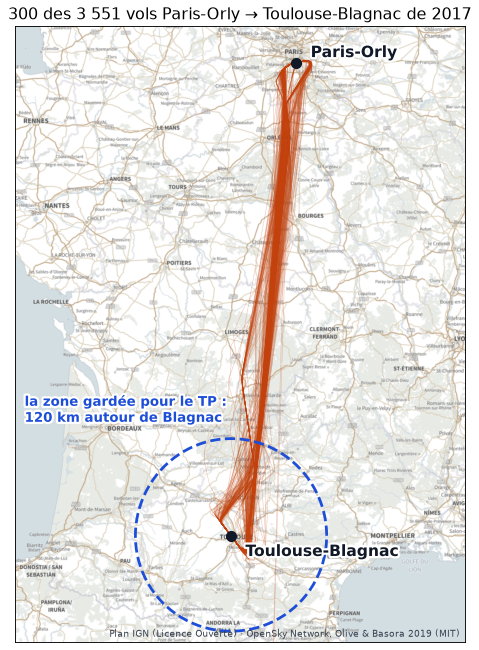</center>

- **ADS-B et OpenSky.** Chaque avion de ligne diffuse par radio, environ deux fois par seconde, sa position, son altitude, sa vitesse et son cap. Le réseau de récepteurs bénévoles OpenSky enregistre ces messages pour la recherche.
- **Le jeu de données.** Tous les vols Paris-Orly → Toulouse-Blagnac de 2017 (X. Olive et L. Basora, ONERA, licence MIT). Nous gardons la fin de chaque vol, dans un cercle de **120 km autour de Blagnac** (le cercle bleu), avec **un point toutes les 10 secondes**.
- **Le nettoyage.** Près du sol, le signal se perd et les mesures deviennent absurdes (38 000 ft pour un avion posé). Chaque vol est donc **coupé à 2 km de l'aéroport**. Il reste **2 825 vols**. Ce genre de problème se découvre en **traçant** les données, avant tout modèle.

> ⚠️ **Attention** · Ce sont des mesures réelles : attentes, raccourcis donnés par le contrôleur, décélérations plus ou moins tôt. Rien n'est simulé.

### 1.2 🔧 Ce que contient un point

Chaque point est une ligne de **6 nombres** :

| Colonne | Unité | Sens | Ordre de grandeur |
|---|---|---|---|
| `x_km` | km | position est-ouest, par rapport à l'aéroport (positif = à l'est) | −120 à +120 |
| `y_km` | km | position nord-sud (positif = au nord) | −120 à +120 |
| `altitude_ft` | pied (ft) | altitude barométrique ; 1 ft = 0,305 m | 25 000 ft à l'entrée, 0 à l'atterrissage |
| `vitesse_sol_kt` | nœud (kt) | vitesse par rapport au sol ; 1 kt = 1,852 km/h | 450 kt en descente, 140 kt en finale |
| `cap_deg` | degré | direction du déplacement : 0 = nord, 90 = est, 180 = sud, 270 = ouest | 0 à 360 |
| `vitesse_verticale_ftmin` | ft/min | négatif quand l'avion descend | −3 000 à +500 |

Pieds, nœuds, ft/min : ce sont les unités du cockpit et de l'écran radar.

> 👀 **À regarder** : les premières lignes de **votre** vol. Toutes les 10 secondes, l'avion avance de combien de km, et descend de combien de pieds ?

In [ ]:
a = vol(VOL)
COLONNES = ['x_km', 'y_km', 'altitude_ft', 'vitesse_sol_kt', 'cap_deg', 'vitesse_verticale_ftmin']
table = pd.DataFrame(a, columns=COLONNES).round(1)
table.insert(0, 'temps', [f'{10 * i // 60} min {10 * i % 60:02d} s' for i in range(len(a))])
print(f'Vol {IDS[VOL]} du {DATES[VOL]} — {len(a)} points, soit {len(a) * 10 / 60:.0f} minutes de vol dans la zone')
display(table.head(8))
print(f"En 10 s : l'avion avance de {np.linalg.norm(a[1, :2] - a[0, :2]):.2f} km (vitesse sol {a[0, 3]:.0f} kt = {a[0, 3] * 1.852:.0f} km/h)")

### 1.3 🔧 Votre vol, sur la carte et dans le temps

**Exécutez la cellule ci-dessous** : elle trace deux vues de votre vol.
- **À gauche**, la trajectoire sur la photo aérienne, colorée par l'altitude, avec une marque toutes les 5 minutes.
- **À droite**, les mêmes points sous forme de **quatre séries temporelles** : l'altitude, la vitesse, le cap et la vitesse verticale au fil du temps. C'est exactement ce que le réseau lira, point par point.

Dans les notations du cours (slide 5), votre vol est **une séquence** x⟨1⟩ … x⟨T_x⟩, où chaque x⟨t⟩ est un point de 6 nombres.

<center>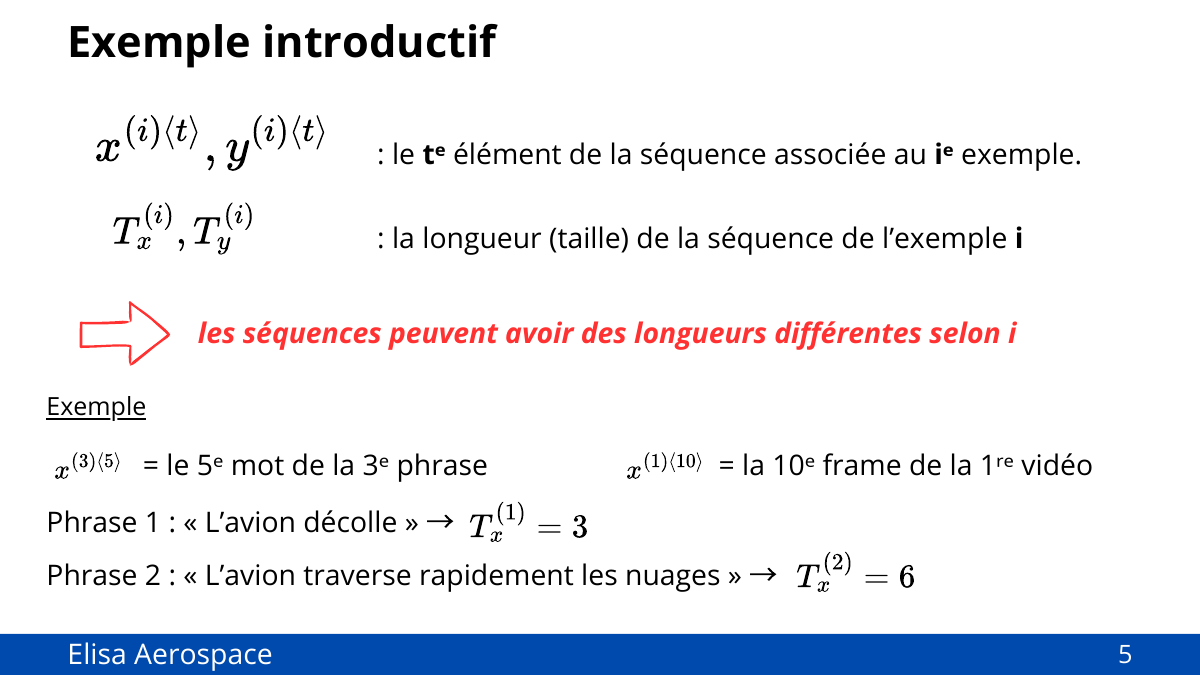</center>

> 👀 **À regarder** : les **phases du vol** sur les courbes (descente, paliers, **virages** quand le cap change, finale), et où elles sont sur la carte.

In [ ]:
a = vol(VOL); t_min = np.arange(len(a)) * 10 / 60
fig = plt.figure(figsize=(16, 7))
ax = fig.add_axes([0, 0, .5, 1])
carte(ax, centre=(a[:, 0].mean(), a[:, 1].mean()), demi=max(np.ptp(a[:, 1]) / 2 + 8, 25))
tracer_vol(ax, a, lw=3.5)
for i in range(0, len(a), 30):                       # une marque toutes les 5 minutes
    ax.plot(*a[i, :2], 'o', color='white', ms=6, zorder=6); ax.text(a[i, 0] + 1, a[i, 1] + 1, f'{i // 6} min', color='white', fontsize=10, zorder=6)
avion(ax, a[-1, 0], a[-1, 1], a[-1, 4], taille=500); barre_altitude(ax)
ax.set_title(f'Vol {IDS[VOL]} — piste {PISTE[VOL]}', fontsize=13)
for k, (col, nom) in enumerate([(2, 'altitude (ft)'), (3, 'vitesse sol (kt)'), (4, 'cap (°)'), (5, 'vitesse verticale (ft/min)')]):
    axk = fig.add_axes([.56, .78 - k * .24, .42, .19])
    axk.plot(t_min, a[:, col], color='#1d4ed8', lw=2); axk.set_ylabel(nom, fontsize=10); axk.grid(alpha=.3)
    if k < 3: axk.set_xticklabels([])
axk.set_xlabel('temps depuis l\'entrée dans la zone (min)')
plt.show()

### 1.4 🔧 Toutes les arrivées, et les deux pistes

Un avion atterrit **face au vent** : selon la météo du jour, tout le monde se pose vers le sud-est (**piste 14**) ou vers le nord-ouest (**piste 32**). Venant de Paris, les avions de la piste 14 obliquent vers l'ouest puis s'alignent ; ceux de la piste 32 contournent l'aéroport par l'est et le sud, puis font demi-tour.

Les vols n'ont pas tous la même durée (slides 5 et 7) : un RNN lit une séquence de n'importe quelle longueur.

> 👀 **À regarder** : la cellule trace 300 arrivées colorées par piste (à gauche) et l'histogramme de leurs durées (à droite). Repérez les deux « couloirs » d'arrivée et la zone où ils se séparent.

In [ ]:
fig = plt.figure(figsize=(16, 7.5))
ax = fig.add_axes([0, 0, .62, 1]); carte(ax, centre=(5, 15), demi=75)
rng = np.random.default_rng(0)
for v in rng.choice(TRAIN, 300, replace=False):
    tracer_vol(ax, vol(v), lw=.8, couleur=ROUGE if PISTE[v] == 14 else BLEU, alpha=.35, zorder=2)
tracer_vol(ax, vol(VOL), lw=3.5, couleur='white', zorder=5)
legende(ax, [('piste 14 (vers le sud-est)', dict(color=ROUGE, lw=2)), ('piste 32 (vers le nord-ouest)', dict(color=BLEU, lw=2)),
             (f'votre vol ({IDS[VOL]})', dict(color='white', lw=3))])
ax.set_title(f'300 arrivées — piste 14 : {np.mean(PISTE == 14):.0%} des vols, piste 32 : {np.mean(PISTE == 32):.0%}', fontsize=13)
axh = fig.add_axes([.68, .15, .3, .7])
longueurs = np.diff(STARTS)
axh.hist(longueurs * 10 / 60, bins=40, color='#1d4ed8'); axh.set_xlabel('durée dans la zone (min)'); axh.set_ylabel('nombre de vols')
axh.set_title(f'T_x varie de {longueurs.min()} à {longueurs.max()} points'); axh.grid(alpha=.3)
plt.show()

---
### ✍️ Réponse R1

> *Prédiction (avant 1.6).* On veut prédire la position de l'avion **2 minutes à l'avance**. Sur la carte de 1.4, **où** cela sera-t-il le plus difficile ? Désignez **deux zones** précises (coordonnées approximatives en km) et dites pourquoi.
>
> *Observation et explication (après 1.6).* Où l'erreur de la règle « vitesse constante » est-elle grande sur votre carte d'erreurs ? Cette règle n'utilise que le **dernier** point : qu'est-ce que les points précédents de la trajectoire pourraient apprendre à un modèle ?

*Votre réponse ici (texte libre, citez vos figures).*

### 1.5 Ce que reçoit le réseau

Le réseau ne lit pas un vol entier d'un coup : on découpe chaque vol en **fenêtres**. Une fenêtre, c'est :
- **en entrée**, les **30 derniers points** (5 minutes de vol) : x⟨1⟩ … x⟨30⟩, donc T_x = 30 ;
- **en sortie**, les **12 points suivants** (2 minutes) : y⟨1⟩ … y⟨12⟩, donc T_y = 12.

On fait glisser la fenêtre le long du vol, tous les 3 points (30 s). Trois transformations, à connaître :

| | Ce qu'on fait | Pourquoi |
|---|---|---|
| **Entrées normalisées** | x et y divisés par 100, altitude par 10 000, vitesse par 300, vitesse verticale par 2 000 | toutes les variables autour de 1 : sinon l'altitude (25 000) écraserait le cap |
| **Cap en sinus et cosinus** | 1 colonne `cap` → 2 colonnes `sin(cap)`, `cos(cap)` | 359° et 1° sont presque le même cap, mais des nombres très éloignés ; (sin, cos) les rend proches |
| **Sortie relative** | on prédit les **déplacements** en km depuis le dernier point connu, pas les positions absolues | « tourner à droite de 3 km » est la même tâche partout sur la carte |

Chaque x⟨t⟩ est donc un vecteur de **7 nombres**, chaque y⟨t⟩ un vecteur de **2 nombres** (déplacement est, déplacement nord).

> 👀 **À regarder** : la forme des tenseurs, et la fenêtre dessinée sur votre vol.

In [ ]:
def features(a):
    """(T, 6) en unités physiques -> (T, 7) normalisé, ce que reçoit le réseau."""
    cap = np.radians(a[:, 4])
    return np.stack([a[:, 0] / 100, a[:, 1] / 100,          # position (km / 100)
                     a[:, 2] / 10000,                       # altitude (ft / 10 000)
                     a[:, 3] / 300,                         # vitesse sol (kt / 300)
                     np.sin(cap), np.cos(cap),              # cap, en sinus et cosinus
                     a[:, 5] / 2000], 1).astype(np.float32) # vitesse verticale (ft/min / 2 000)

def fenetres(vols, L=30, H=12, pas=3):
    """Découpe les vols en fenêtres : L points d'entrée -> les H points suivants.
    Renvoie X (N, L, 7), Y (N, H, 2) = déplacements en km depuis le dernier point d'entrée,
    et REF (N, 2) = (numéro du vol, indice du dernier point d'entrée dans ce vol)."""
    xs, ys, ref = [], [], []
    for v in vols:
        a = vol(v); f = features(a)
        for t in range(L - 1, len(a) - H, pas):
            xs.append(f[t - L + 1:t + 1]); ys.append(a[t + 1:t + H + 1, :2] - a[t, :2]); ref.append((v, t))
    return torch.tensor(np.array(xs)), torch.tensor(np.array(ys), dtype=torch.float32), np.array(ref)

def erreur_par_horizon(pred, Y):
    """Distance moyenne (km) entre prédiction et vérité, pour chaque pas de l'horizon."""
    pred, Y = np.asarray(pred), np.asarray(Y)
    return np.linalg.norm(pred - Y, axis=-1).mean(0)

Xtr, Ytr, Rtr = fenetres(TRAIN)          # fenêtres de 30 points -> 12 points, tous les 3 points
Xva, Yva, Rva = fenetres(VAL, pas=6)
Xte, Yte, Rte = fenetres(TEST)
print('entrées  X :', tuple(Xtr.shape), '= (fenêtres, 30 pas de temps, 7 variables)')
print('sorties  Y :', tuple(Ytr.shape), '= (fenêtres, 12 pas de temps, déplacement est et nord en km)')
print(f'{len(Xtr)} fenêtres d\'entraînement, {len(Xva)} de validation, {len(Xte)} de test')

# une fenêtre de votre vol, dessinée
a = vol(VOL); t = 29 + 3 * ((len(a) - 42) // 6)              # une fenêtre au milieu du vol
ax = carte(centre=tuple(a[t, :2]), demi=18, taille=(12, 6.5))
tracer_vol(ax, a, lw=1.5, couleur='white', alpha=.4)
ax.plot(a[t - 29:t + 1, 0], a[t - 29:t + 1, 1], 'o-', color='#fbbf24', ms=4, lw=2, zorder=6)
ax.plot(a[t + 1:t + 13, 0], a[t + 1:t + 13, 1], 'o-', color=VERT, ms=4, lw=2, zorder=6)
avion(ax, a[t, 0], a[t, 1], a[t, 4], taille=500)
legende(ax, [('entrée : 30 points = 5 min', dict(color='#fbbf24', marker='o', lw=2)), ('à prédire : 12 points = 2 min', dict(color=VERT, marker='o', lw=2))])
plt.show()
print('premiers pas de cette fenêtre, normalisés :'); print(np.round(features(a)[t - 29:t - 26], 3))

### 1.6 ✏️ Une première référence : la vitesse constante

Avant d'entraîner un réseau, il faut savoir ce que fait **une règle simple**. Sinon, impossible de dire si 1 km d'erreur, c'est bien ou mal. La règle la plus simple : l'avion continue tout droit, à la même vitesse.

> ✏️ **À compléter** : la fonction `vitesse_constante(a_t)` reçoit le dernier point connu et renvoie les 12 déplacements (12, 2) en km. En 10 s, l'avion parcourt `vitesse_sol_kt × 1,852 / 3 600 × 10` km, dans la direction de son cap : `sin(cap)` vers l'est, `cos(cap)` vers le nord.

> 👀 **À regarder** : la courbe d'erreur selon l'horizon, et **où** l'erreur à 2 min est grande sur la carte.

In [ ]:
def vitesse_constante(a_t, H=12):
    # a_t = (x, y, altitude, vitesse_sol_kt, cap_deg, vz) : le dernier point connu
    # ... À COMPLÉTER ...

pred_cv = np.array([vitesse_constante(vol(v)[t]) for v, t in Rte])
err_cv = erreur_par_horizon(pred_cv, Yte)
print('erreur moyenne (km) à 10 s, 1 min, 2 min :', err_cv[0].round(2), err_cv[5].round(2), err_cv[-1].round(2))

fig = plt.figure(figsize=(16, 6.5))
ax1 = fig.add_axes([.04, .12, .3, .78])
ax1.plot(np.arange(1, 13) * 10, err_cv, 'o-', color='#6b7280', label='vitesse constante')
ax1.set_xlabel('horizon (s)'); ax1.set_ylabel('erreur moyenne (km)'); ax1.grid(alpha=.3); ax1.legend()
ax2 = fig.add_axes([.38, 0, .62, 1]); carte(ax2, centre=(5, 15), demi=75)
e2 = np.linalg.norm(pred_cv[:, -1] - Yte[:, -1].numpy(), axis=1)
dern = np.array([vol(v)[t, :2] for v, t in Rte])
sc = ax2.scatter(dern[:, 0], dern[:, 1], c=np.clip(e2, 0, 10), cmap='inferno', s=4, zorder=4)
cb = plt.colorbar(sc, ax=ax2, fraction=.03, pad=.01); cb.set_label('erreur à 2 min (km)')
ax2.set_title('Erreur à 2 min de la vitesse constante, selon la position de l\'avion')
plt.show()

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""    d = a_t[3] * 1.852 / 3600 * 10                       # km parcourus en 10 s
    cap = math.radians(a_t[4])
    k = np.arange(1, H + 1)[:, None]                     # 1, 2, ..., 12 pas de 10 s
    return k * d * np.array([math.sin(cap), math.cos(cap)])""")

### 1.7 🔧 Pourquoi découper par vol ?

Les fenêtres d'un même vol se chevauchent : deux fenêtres voisines partagent 27 points sur 30. Le découpage train / val / test a donc été fait **par vol** : tous les vols de test sont des vols que le réseau n'a jamais vus, ni en entier, ni en morceaux.

> 👀 **À regarder** : le chevauchement de deux fenêtres voisines, et le fait qu'aucun vol n'est dans deux ensembles à la fois.

In [ ]:
x0, x1 = Xtr[0].numpy(), Xtr[1].numpy()
communs = sum(any(np.allclose(x1[i], x0[j]) for j in range(30)) for i in range(30))
print(f'deux fenêtres voisines du même vol partagent {communs} points sur 30')
print('vols communs train/test :', len(set(Rtr[:, 0]) & set(Rte[:, 0])), '| train/val :', len(set(Rtr[:, 0]) & set(Rva[:, 0])))

---
### ✍️ Réponse R2

> - Pourquoi découpe-t-on train / val / test **par vol** et pas par fenêtre ? Si l'on mélangeait les fenêtres au hasard, l'erreur de test serait-elle trop optimiste ou trop pessimiste ?
> - Quel type d'architecture des slides 15–16 faut-il pour lire 30 points et en produire 12 ? Donnez T_x et T_y.

*Votre réponse ici (texte libre, citez vos figures).*

---
## Bloc 2 — Ouvrir la cellule (20 min)

### 2.1 ✏️ Un RNN écrit à la main

<center>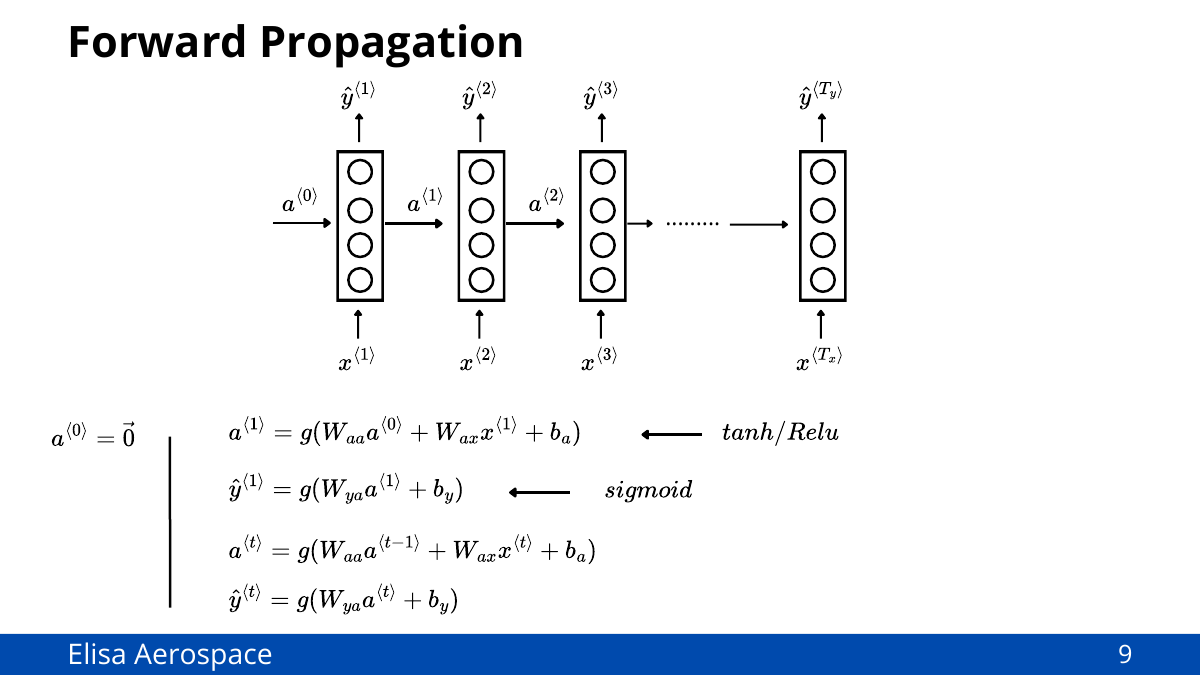</center>

À chaque pas de temps, la cellule RNN combine le point qu'elle lit, x⟨t⟩, et sa mémoire du pas précédent, a⟨t−1⟩ :

**a⟨t⟩ = tanh(W_ax x⟨t⟩ + W_aa a⟨t−1⟩ + b_a)**, avec a⟨0⟩ = 0.

Ici x⟨t⟩ a 7 composantes et a⟨t⟩ en a 64 (la taille de la mémoire) : W_ax est une matrice (64, 7), W_aa une matrice (64, 64).

> ✏️ **À compléter** : la ligne qui calcule a⟨t⟩ dans la boucle. On vérifie ensuite que vos états sont **exactement** ceux de `nn.RNN` de PyTorch, avec les mêmes poids.

> ⚠️ **Attention** · PyTorch a deux biais (`bias_ih` et `bias_hh`) là où le cours n'en a qu'un : leur somme joue le rôle de b_a.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul><li><code>rnn.weight_ih_l0</code> = W_ax (64, 7), <code>rnn.weight_hh_l0</code> = W_aa (64, 64). <code>_l0</code> = couche 0.</li><li><code>.detach()</code> sort un tenseur du graphe de calcul : on n'a pas besoin de gradient ici.</li><li><code>@</code> est le produit matrice-vecteur.</li></ul>
📖 <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html">torch.nn.RNN</a>
</details>

In [ ]:
def rnn_a_la_main(x, Wax, Waa, ba):
    # x : (L, 7) une fenêtre. Renvoie les L états a<1>..a<L>, tableau (L, 64).
    a = torch.zeros(Waa.shape[0])                     # a<0> = 0
    etats = []
    for t in range(x.shape[0]):
        # ... À COMPLÉTER ...
        etats.append(a)
    return torch.stack(etats)

torch.manual_seed(SEED)
rnn = nn.RNN(7, 64, batch_first=True)
Wax, Waa = rnn.weight_ih_l0.detach(), rnn.weight_hh_l0.detach()
ba = (rnn.bias_ih_l0 + rnn.bias_hh_l0).detach()
x = Xtr[0]                                            # une fenêtre : (30, 7)
etats_main = rnn_a_la_main(x, Wax, Waa, ba)
out, h_n = rnn(x[None])                               # PyTorch attend un lot : (1, 30, 7)
print('vos états :', tuple(etats_main.shape), '| identiques à nn.RNN :', torch.allclose(etats_main, out[0].detach(), atol=1e-5))

In [ ]:
#@title 🔒 Solution (à ouvrir après 5 min d’essai, double-clic pour afficher) { display-mode: "form" }
print("""        a = torch.tanh(Wax @ x[t] + Waa @ a + ba)""")

### 2.2 🔧 `out` et `h_n` : tous les états, ou seulement le dernier

`nn.RNN` renvoie deux choses :
- **`out`** : l'état a⟨t⟩ à **chaque** pas, forme `(B, L, 64)`. C'est ce qu'il faut pour un *many-to-many* ;
- **`h_n`** : le **dernier** état seulement, forme `(couches, B, 64)`. C'est le résumé de toute la séquence, ce qu'utilise un *many-to-one*.

> 👀 **À regarder** : les deux formes, et le fait que le dernier état de `out` est exactement `h_n`.

In [ ]:
print('out :', tuple(out.shape), '| h_n :', tuple(h_n.shape))
print('le dernier état de out est h_n :', torch.allclose(out[:, -1], h_n[0]))

---
### ✍️ Réponse R3

> - Dans `rnn_a_la_main`, la variable `a` est écrasée à chaque tour de boucle, et pourtant le réseau a une mémoire. Que contient a⟨30⟩ que le dernier point x⟨30⟩ ne contient pas ? Donnez un exemple sur une trajectoire.
> - Le modèle « sortie directe » utilisé en 2.4 et au bloc 3 prédit les 12 points à partir de `h_n` **seul**, sans relire les 30 points. Pourquoi est-ce possible, et quelle limite cela impose-t-il ?

*Votre réponse ici (texte libre, citez vos figures).*

### 2.3 🔧 Nombre de paramètres

In [ ]:
for nom in ['RNN', 'GRU', 'LSTM']:
    cel = getattr(nn, nom)(7, 64, batch_first=True)
    formes = {n: tuple(p.shape) for n, p in cel.named_parameters()}
    print(f'{nom:5s} {sum(p.numel() for p in cel.parameters()):6d} paramètres  {formes}')

### 2.4 🔧 Un même réseau pour toutes les longueurs

Les poids W_ax, W_aa, b_a sont **les mêmes à chaque pas de temps** : la cellule est appliquée 30 fois, ou 90, ou 3, avec les mêmes poids. Un même RNN peut donc lire un historique de n'importe quelle longueur.

On a entraîné pour vous un GRU (fichier `gru_longueurs_variees.pt`) en lui donnant, à chaque lot, un historique de longueur différente, de 30 secondes à 15 minutes. On l'évalue ici sur les **mêmes** instants de prédiction, en ne changeant que la longueur d'historique qu'on lui donne.

C'est utile en vrai : un avion qui vient d'apparaître sur l'écran radar n'a que quelques points d'historique.

> 👀 **À regarder** : la cellule trace, à gauche, l'erreur à 2 min selon la longueur d'historique et, à droite, trois prédictions sur votre vol, juste avant son plus grand virage.

In [ ]:
def charger(nom, modele):
    modele.load_state_dict(torch.load(DATA / 'secours' / f'{nom}.pt', map_location='cpu'))
    return modele.to(DEVICE).eval()

class Direct(nn.Module):
    """Many-to-one : une cellule récurrente lit la fenêtre, son dernier état h_n prédit les H déplacements d'un coup."""
    def __init__(self, cellule='GRU', n_entrees=7, n_cache=64, H=12):
        super().__init__()
        self.H = H
        self.rnn = getattr(nn, cellule)(n_entrees, n_cache, batch_first=True)   # nn.RNN, nn.GRU ou nn.LSTM
        self.sortie = nn.Linear(n_cache, 2 * H)
    def forward(self, x):
        out, h_n = self.rnn(x)
        if isinstance(h_n, tuple):           # le LSTM renvoie (h_n, c_n)
            h_n = h_n[0]
        return self.sortie(h_n[-1]).view(-1, self.H, 2)

def predire(modele, X, lot=2048):
    modele.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), lot):
            out.append(modele(X[i:i + lot].to(DEVICE)).cpu())
    return torch.cat(out).numpy()

def entrainer(modele, Xtr, Ytr, Xval, Yval, epochs=5, lr=2e-3, lot=256, **options):
    """Boucle d'entraînement générique (Adam, perte MSE en km²). Renvoie l'historique des pertes."""
    modele.to(DEVICE); opt = torch.optim.Adam(modele.parameters(), lr=lr)
    hist = {'train': [], 'val': []}; t0 = time.time()
    for ep in range(epochs):
        modele.train(); perm = torch.randperm(len(Xtr)); total = 0.
        for i in range(0, len(Xtr), lot):
            idx = perm[i:i + lot]; x, y = Xtr[idx].to(DEVICE), Ytr[idx].to(DEVICE)
            p = modele(x, y, **options) if options else modele(x)
            perte = ((p - y) ** 2).mean()
            opt.zero_grad(); perte.backward(); opt.step(); total += perte.item() * len(idx)
        hist['train'].append(total / len(Xtr))
        hist['val'].append(float(((predire(modele, Xval) - Yval.numpy()) ** 2).mean()))
        print(f"  epoch {ep + 1}/{epochs}  perte train {hist['train'][-1]:.3f}  val {hist['val'][-1]:.3f}  ({time.time() - t0:.0f} s)")
    return hist

gru_var = charger('gru_longueurs_variees', Direct('GRU'))
X90, Y90, R90 = fenetres(TEST, L=90, pas=6)       # 15 min d'historique disponibles
longueurs = [3, 6, 12, 18, 30, 60, 90]
err_L = [erreur_par_horizon(predire(gru_var, X90[:, -L:]), Y90)[-1] for L in longueurs]

fig = plt.figure(figsize=(16, 6.5))
ax1 = fig.add_axes([.04, .12, .3, .78])
ax1.plot([L / 6 for L in longueurs], err_L, 'o-', color='#1d4ed8', lw=2)
ax1.set_xscale('log'); ax1.set_xticks([.5, 1, 2, 3, 5, 10, 15]); ax1.set_xticklabels(['30 s', '1', '2', '3', '5', '10', '15 min'])
ax1.set_xlabel("longueur d'historique donnée au GRU"); ax1.set_ylabel('erreur moyenne à 2 min (km)'); ax1.grid(alpha=.3)
for L, e in zip(longueurs, err_L): ax1.annotate(f'{e:.2f}', (L / 6, e), textcoords='offset points', xytext=(0, 8), ha='center')

a = vol(VOL); hd = a[:, 4]
t = max(range(min(89, len(a) - 13), len(a) - 12), key=lambda t: abs(((hd[t + 12] - hd[t]) + 180) % 360 - 180))   # l'instant qui précède le plus grand virage
ax2 = fig.add_axes([.38, 0, .62, 1]); carte(ax2, centre=tuple(a[t, :2]), demi=14)
tracer_vol(ax2, a[:t + 1], lw=3); ax2.plot(a[t:t + 13, 0], a[t:t + 13, 1], color='white', lw=2.2, ls=(0, (3, 2)), zorder=6)
f = torch.tensor(features(a))
for L, c in [(3, '#f43f5e'), (12, '#fbbf24'), (90, VERT)]:
    p = predire(gru_var, f[max(0, t - L + 1):t + 1][None])[0]
    ax2.plot(*np.r_[[a[t, :2]], a[t, :2] + p].T, color=c, lw=3, zorder=7)
avion(ax2, a[t, 0], a[t, 1], a[t, 4], taille=500)
legende(ax2, [('futur réel', dict(color='white', lw=2, ls=(0, (3, 2)))), ('prédit avec 30 s', dict(color='#f43f5e', lw=3)),
              ('prédit avec 2 min', dict(color='#fbbf24', lw=3)), ('prédit avec 15 min', dict(color=VERT, lw=3))])
plt.show()

---
### ✍️ Réponse R4

> - Retrouvez **à la main** les 4 672 paramètres de `nn.RNN(7, 64)` affichés en 2.3 (formule de la slide 9 ; PyTorch a deux biais). Pourquoi ce nombre ne dépend-il pas de la longueur de la fenêtre ?
> - En 2.4, le **même** réseau lit 30 secondes ou 15 minutes d'historique. De combien d'historique a-t-il **vraiment** besoin pour prédire 2 minutes, et pourquoi la courbe devient-elle plate ensuite ?

*Votre réponse ici (texte libre, citez vos figures).*

---
## Bloc 3 — Mémoire courte, mémoire longue (30 min)

<center>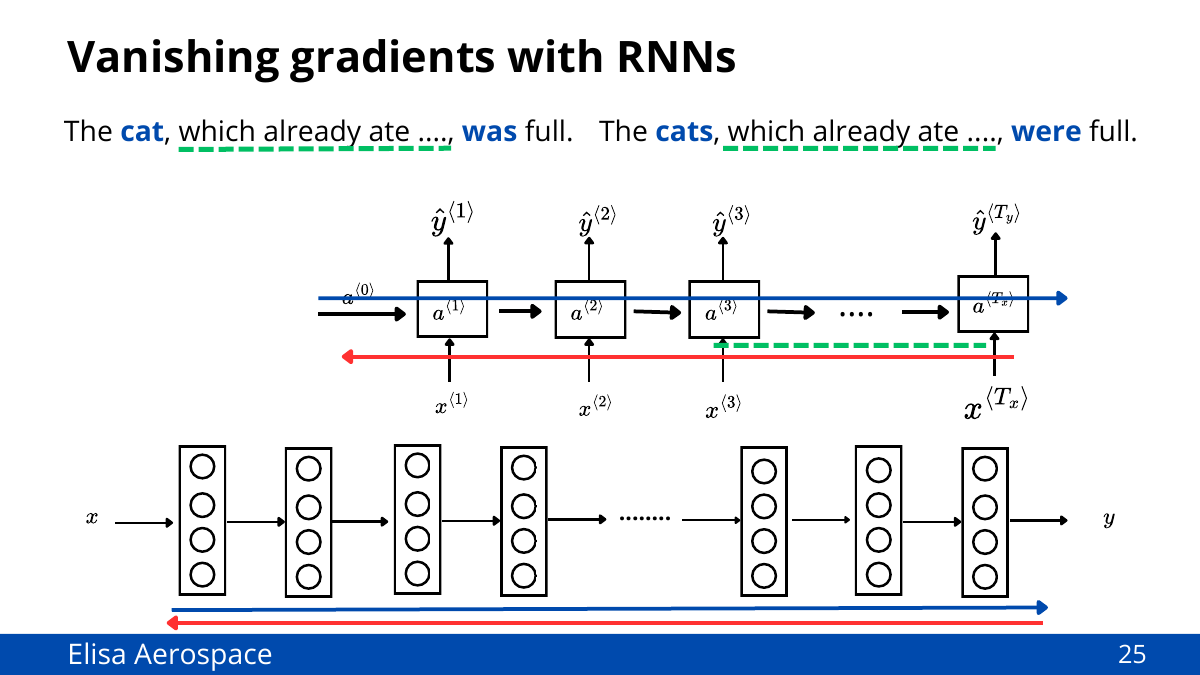</center>

Pour apprendre, le gradient de l'erreur doit remonter **de la sortie jusqu'aux premiers points** de la fenêtre, en traversant les cellules une à une, de droite à gauche. Dans un RNN simple, chaque traversée le multiplie par W_aa et par une dérivée de tanh (slide 25).

Le GRU et le LSTM ajoutent un **chemin additif** pour la mémoire : c⟨t⟩ = Γu ⊙ c̃⟨t⟩ + Γf ⊙ c⟨t−1⟩. Quand la porte d'oubli Γf vaut presque 1, la mémoire passe d'un pas à l'autre presque sans perte (slides 29 et 31).

<center>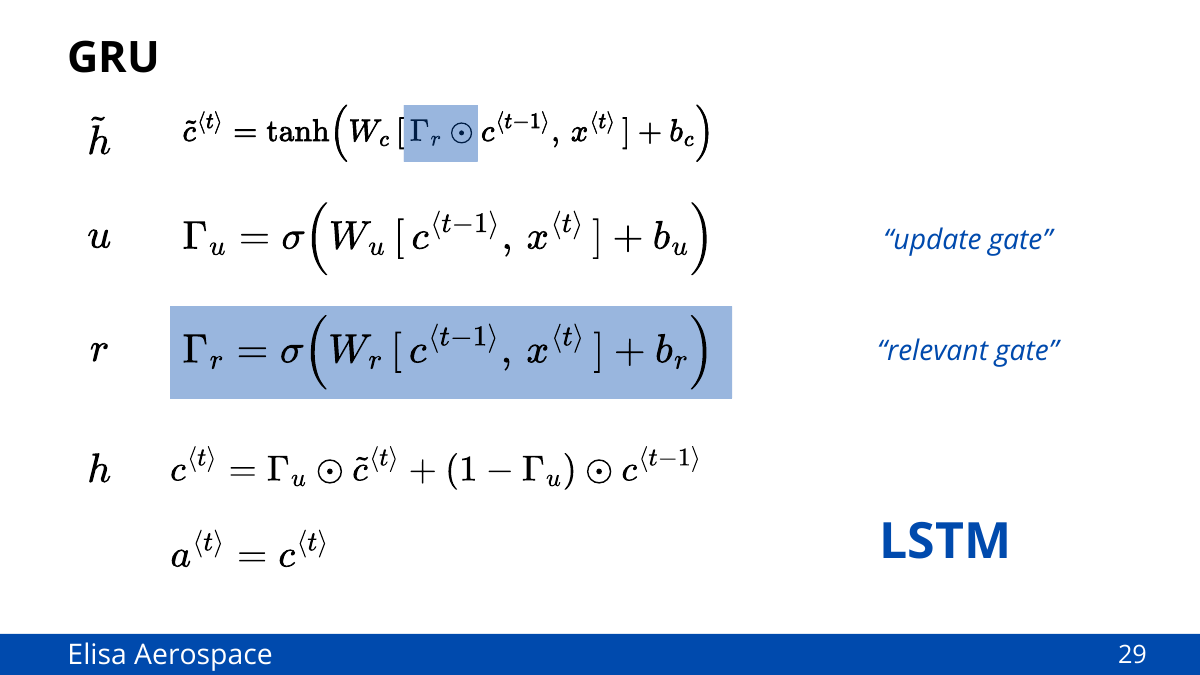<br>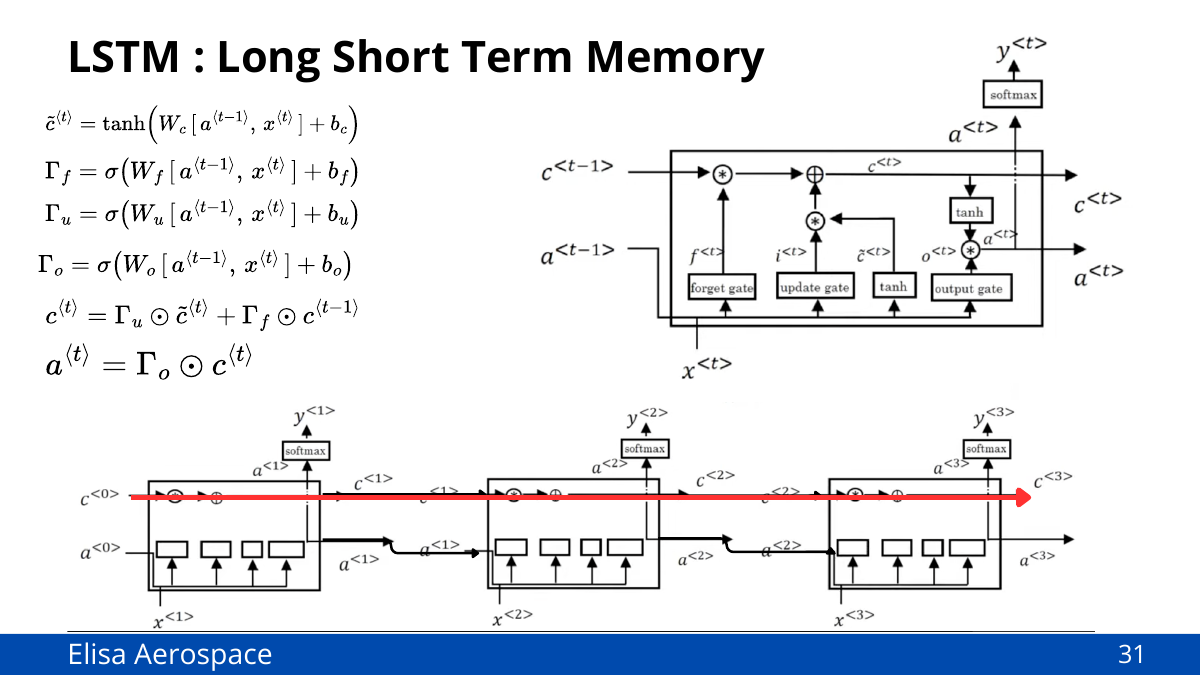</center>

> 🧪 **L'expérience.** On entraîne un RNN, un GRU et un LSTM de même taille (64) sur des fenêtres de **`L_LONG` points** (votre longueur, 7,5 à 15 min). Puis on mesure, pour chacun, l'**influence** de chaque point de la fenêtre sur l'erreur :

<center>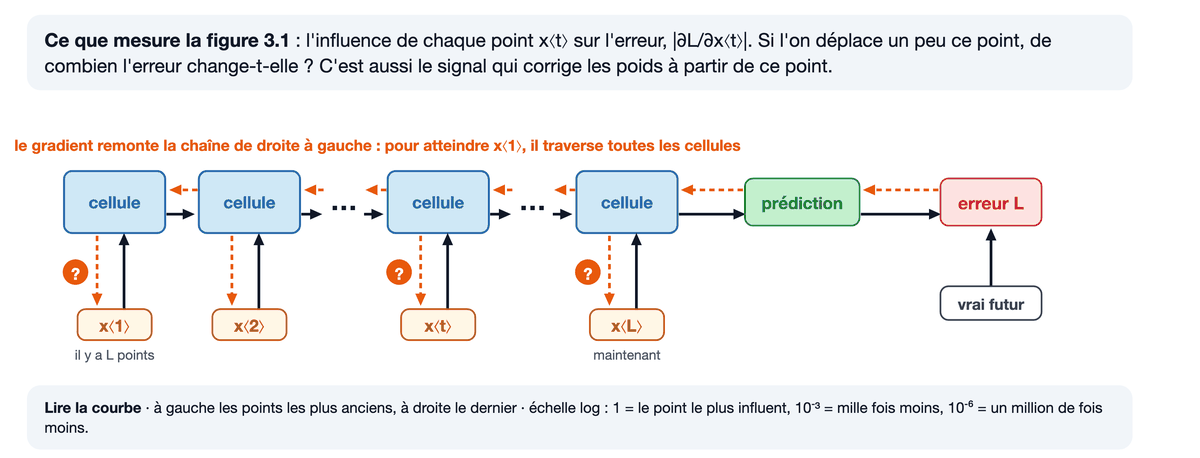</center>

---
### ✍️ Réponse R5

> *Prédiction (avant 3.1).* Comment l'influence d'un point devrait-elle évoluer quand on remonte vers le **début** de la fenêtre, pour le RNN et pour le LSTM ? Justifiez avec le chemin que suit le gradient dans chaque cellule (slides 25 et 31).
>
> *Observation et explication (après 3.1).* Combien d'**ordres de grandeur** séparent le RNN du LSTM au début de **votre** fenêtre ? Qu'est-ce que cela veut dire pour l'apprentissage : de quels points chaque réseau peut-il encore apprendre quelque chose ?

*Votre réponse ici (texte libre, citez vos figures).*

### 3.1 🔧 Entraîner les trois cellules et mesurer l'influence de chaque point

Environ 2 minutes sur GPU. **Secours** : cochez `UTILISER_SECOURS` pour charger des poids déjà entraînés sur votre longueur `L_LONG` au lieu d'entraîner.

> 👀 **À regarder** : une courbe par réseau, **après entraînement**. Lisez la hauteur de chaque courbe tout à **gauche**, au point le plus ancien de votre fenêtre ; la cellule écrit aussi ces valeurs en clair sous la figure. L'échelle verticale est **logarithmique** : chaque graduation divise par 100.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul><li><code>Direct(cellule)</code> : la cellule lit la fenêtre, son dernier état <code>h_n</code> passe dans une couche linéaire qui sort les 24 nombres (12 déplacements × 2). C'est un <i>many-to-one</i>.</li><li><code>gradient_par_pas</code> : on rend l'entrée <code>x</code> « dérivable » (<code>requires_grad_</code>), on calcule la perte, <code>backward()</code>, puis on lit <code>x.grad</code> : la sensibilité de la perte à chaque point. On la divise par son maximum, d'où « 1 = le point le plus influent ».</li><li><code>entrainer</code> : boucle classique, optimiseur Adam, perte MSE en km².</li></ul>
📖 <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html">nn.GRU</a> · <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html">nn.LSTM</a> · <a href="https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html">autograd</a>
</details>

In [ ]:
UTILISER_SECOURS = False  #@param {type:"boolean"}

def gradient_par_pas(modele, X, Y, n=512):
    """|dL/dx<t>| moyen pour chaque pas t de la fenêtre, normalisé par son maximum."""
    modele.to(DEVICE).train()                       # le backward des RNN cuDNN exige le mode train
    x = X[:n].clone().to(DEVICE).requires_grad_(True)
    perte = ((modele(x) - Y[:n].to(DEVICE)) ** 2).mean(); perte.backward()
    g = x.grad.norm(dim=2).mean(0).cpu().numpy(); modele.zero_grad()
    return np.maximum(g / g.max(), 1e-30)          # plancher : 0 n'existe pas en échelle log

X3tr, Y3tr, _ = fenetres(TRAIN, L=L_LONG, pas=4)
X3va, Y3va, _ = fenetres(VAL, L=L_LONG, pas=8)
X3te, Y3te, _ = fenetres(TEST, L=L_LONG, pas=6)
influence, err3 = {}, {}
for cel in ['RNN', 'GRU', 'LSTM']:
    torch.manual_seed(SEED); m = Direct(cel)
    if UTILISER_SECOURS:
        charger(f'direct_{cel}_L{L_LONG}', m)
    else:
        print(cel); entrainer(m, X3tr, Y3tr, X3va, Y3va, epochs=6)
    influence[cel] = gradient_par_pas(m, X3te, Y3te)          # influence de chaque point ; la plus forte vaut 1
    err3[cel] = erreur_par_horizon(predire(m, X3te), Y3te)[-1]

tt = (np.arange(L_LONG) - L_LONG + 1) / 6                        # minutes avant le dernier point
duree = f'{L_LONG / 6:g}'.replace('.', ',')
fig, ax = plt.subplots(figsize=(13, 6))
for cel, c in [('RNN', '#dc2626'), ('GRU', '#1d4ed8'), ('LSTM', '#15803d')]:
    ax.semilogy(tt, influence[cel], color=c, lw=3, label=cel)
k_min = int(np.ceil(-np.log10(min(g.min() for g in influence.values()))))
ticks = [10.0 ** -k for k in range(0, k_min + 2, 2)]
ax.set_yticks(ticks); ax.set_yticklabels(['1 = le plus influent'] + [f'10$^{{-{k}}}$' for k in range(2, k_min + 2, 2)])
ax.minorticks_off(); ax.set_ylim(ticks[-1], 3)
ax.set_xlabel('position du point dans votre fenêtre (minutes avant le dernier point)')
ax.set_ylabel("influence du point sur l'erreur")
ax.set_title("Après entraînement : de combien l'erreur dépend-elle de chaque point de la fenêtre ?")
ax.text(.01, .03, f'◀ le point le plus ancien (il y a {duree} min)', transform=ax.transAxes, fontsize=11)
ax.text(.99, .03, 'le dernier point ▶', transform=ax.transAxes, ha='right', fontsize=11)
ax.grid(alpha=.3); ax.legend(loc='center right', fontsize=12)
plt.show()
print(f'Influence du point le plus ancien (il y a {duree} min), comparée au point le plus influent :')
for cel, g in influence.items():
    print(f'  {cel:5s} {g[0]:.0e}, soit environ 1 / ' + f'{1 / g[0]:,.0f}'.replace(',', ' '))
print('erreur à 2 min (km) :', {c: round(float(e), 2) for c, e in err3.items()})

---
### ✍️ Réponse R6

> - Le LSTM garde une influence des milliers de fois plus forte que le RNN au début de la fenêtre. Pourquoi son erreur à 2 minutes (dernière ligne de 3.1) n'est-elle pas meilleure dans les mêmes proportions ? Appuyez-vous sur la courbe de 2.4.
> - Donnez un **cas d'usage aéronautique** où une mémoire longue serait indispensable, et dites ce que le réseau devrait se rappeler.

*Votre réponse ici (texte libre, citez vos figures).*

### 3.2 🎁 Bonus — Et avant l'entraînement ?

Les courbes de 3.1 sont celles de réseaux **entraînés**. La cellule trace celle d'un LSTM **qui n'a encore rien appris**, puis la même avec le biais de la porte d'oubli mis à 1 (choix par défaut de Keras ; dans PyTorch, `bias_ih_l0[64:128]` est le biais de la porte d'oubli), et les compare à votre LSTM entraîné. Qu'a appris le LSTM pendant l'entraînement ?

In [ ]:
torch.manual_seed(SEED); lstm0 = Direct('LSTM')                  # mêmes poids de départ qu'en 3.1
torch.manual_seed(SEED); lstm1 = Direct('LSTM')
with torch.no_grad():
    lstm1.rnn.bias_ih_l0[64:128] = 1.0                            # σ(1) ≈ 0,73 au lieu de σ(0) = 0,5
plt.figure(figsize=(10, 4.5))
plt.semilogy(tt, gradient_par_pas(lstm0, X3te, Y3te), label="LSTM non entraîné, biais d'oubli = 0")
plt.semilogy(tt, gradient_par_pas(lstm1, X3te, Y3te), label="LSTM non entraîné, biais d'oubli = 1")
plt.semilogy(tt, influence['LSTM'], color='#15803d', lw=3, label='LSTM entraîné (3.1)')
plt.xlabel('minutes avant le dernier point'); plt.ylabel("influence du point sur l'erreur")
plt.legend(); plt.grid(alpha=.3); plt.show()

---
## Bloc 4 — Générer la suite : l'encodeur-décodeur (40 min)

### 4.1 🔧 L'encodeur-décodeur

Jusqu'ici, le réseau sortait les 12 points **d'un coup** : une couche linéaire branchée sur `h_n` produisait directement 24 nombres. On passe maintenant à l'architecture de la traduction (slide 16), où **deux** réseaux récurrents se partagent le travail. L'animation montre les étapes une par une :

<center>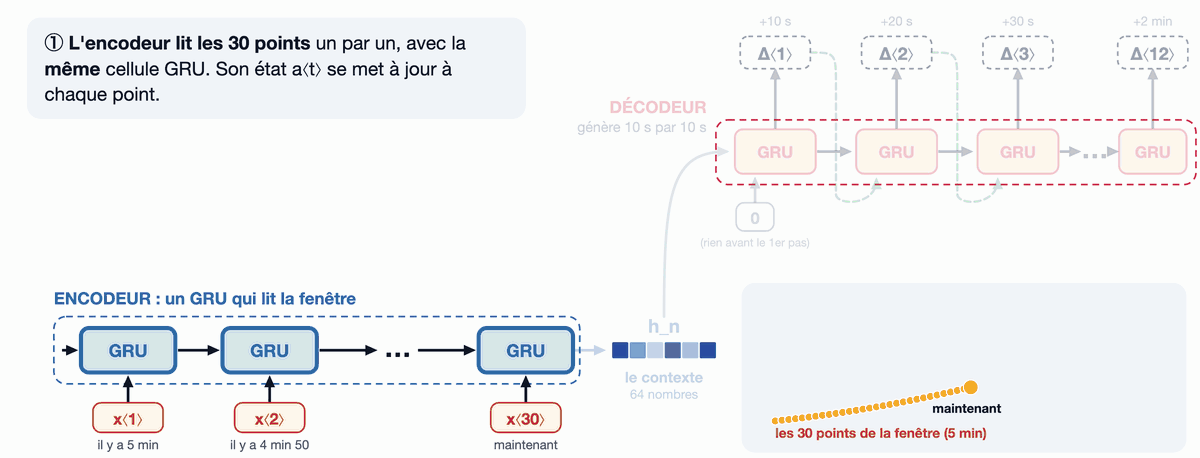</center>

- l'**encodeur** lit la fenêtre, point par point ; il ne prédit rien ;
- son dernier état `h_n`, le **contexte**, est le seul lien entre les deux réseaux ;
- le **décodeur** génère la suite **10 secondes par 10 secondes**. À chaque pas, il reçoit le déplacement qu'il vient de produire, comme un modèle de langage reçoit le mot qu'il vient d'écrire.

> 👀 **À regarder** : dans le code, la boucle `for t in range(self.H)`, qui génère les 12 pas l'un après l'autre. Repérez la ligne où la sortie d'un pas devient l'entrée du suivant.

<details><summary><b>Détail du code et documentation</b> (à ouvrir si besoin)</summary>
<ul><li><code>self.encodeur(x)</code> renvoie tous les états a⟨t⟩ (forme (B, 30, 64)) et <code>h_n</code> (le dernier). On n'utilise que <code>h_n</code>, d'où le <code>_</code>.</li><li><code>nn.GRUCell</code> fait <b>un seul pas</b> de GRU : c'est ce qu'il faut quand on génère pas à pas, car l'entrée du pas t dépend de la sortie du pas t−1.</li><li>Le décodeur sort un déplacement de 10 s ; on les additionne pour obtenir la position relative au dernier point connu.</li></ul>
📖 <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.GRUCell.html">nn.GRUCell</a> · <a href="https://docs.pytorch.org/tutorials/intermediate/seq2seq_translation_tutorial.html">tutoriel seq2seq PyTorch</a>
</details>

In [ ]:
class Seq2Seq(nn.Module):
    """Encodeur-décodeur. L'encodeur (GRU) lit les L points ; le décodeur (GRUCell) génère les H déplacements un par un.
    À chaque pas, le décodeur reçoit le déplacement du pas précédent : le vrai (teacher forcing) ou le sien (génération libre)."""
    def __init__(self, n_entrees=7, n_cache=64, H=12):
        super().__init__()
        self.H = H
        self.encodeur = nn.GRU(n_entrees, n_cache, batch_first=True)
        self.decodeur = nn.GRUCell(2, n_cache)       # un seul pas de GRU : l'entrée du pas t dépend de la sortie du pas t-1
        self.sortie = nn.Linear(n_cache, 2)
    def forward(self, x, y=None, teacher_forcing=False):
        _, h_n = self.encodeur(x)                    # h_n : (1, B, 64), le dernier état de l'encodeur
        h = h_n[0]                                   # vecteur de contexte = résumé de tout le passé
        prec = torch.zeros(x.size(0), 2, device=x.device)   # « déplacement précédent » du premier pas : zéro
        pos = torch.zeros_like(prec); sorties = []
        for t in range(self.H):
            h = self.decodeur(prec, h)
            pas = self.sortie(h)                     # déplacement des 10 prochaines secondes
            pos = pos + pas; sorties.append(pos)
            if teacher_forcing and y is not None:
                prec = y[:, t] - (y[:, t - 1] if t > 0 else 0)   # le vrai déplacement
            else:
                prec = pas                                       # sa propre prédiction
        return torch.stack(sorties, 1)

m = Seq2Seq()
p = m(Xtr[:4])
print('entrée', tuple(Xtr[:4].shape), '-> sortie', tuple(p.shape), '| paramètres :', sum(q.numel() for q in m.parameters()))

---
### ✍️ Réponse R7

> - Que reçoit le décodeur à son **premier** pas, puis à chacun des pas suivants ? D'où vient son état de départ, et qu'est-ce qui passe d'un pas au suivant ?
> - Le modèle « sortie directe » du bloc 3 sortait les 12 points d'un coup. Que peut faire le décodeur que la sortie directe ne peut pas ? Pensez à un horizon de 4 minutes au lieu de 2, et à la façon dont le 2e point dépend du 1er.

*Votre réponse ici (texte libre, citez vos figures).*

### 4.2 Teacher forcing ou génération libre ?

À chaque pas, le décodeur a besoin du déplacement du pas précédent. **Pendant l'entraînement**, on connaît les 12 vrais déplacements de chaque fenêtre : on peut donc **choisir** ce qu'on lui donne.

<center>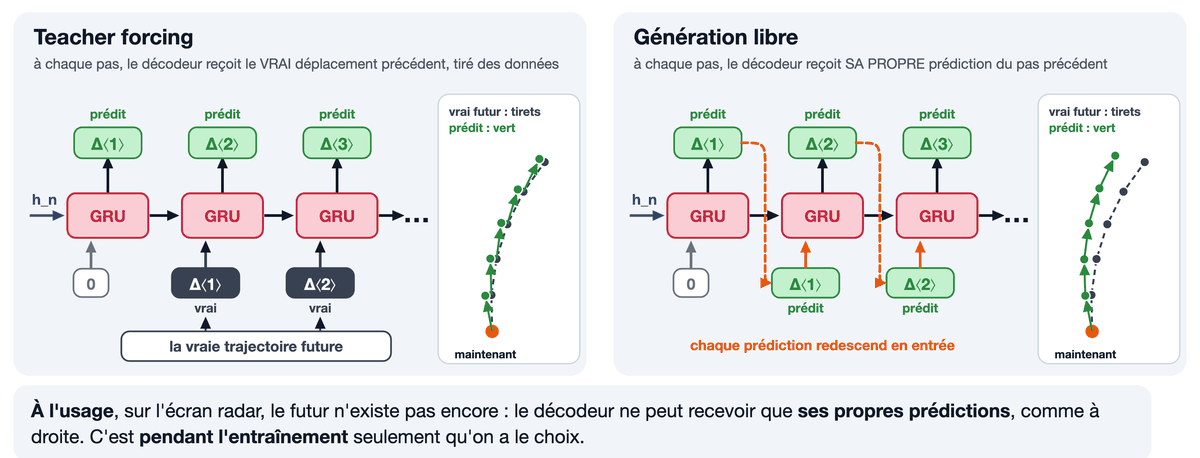</center>

| | Ce que reçoit le décodeur au pas t | S'il s'est trompé au pas t − 1… |
|---|---|---|
| **Teacher forcing** (slide 20) | le **vrai** déplacement du pas t − 1, tiré des données | … le pas t repart quand même de la vérité |
| **Génération libre** (slide 21) | **sa propre** prédiction du pas t − 1 | … le pas t part de cette erreur |

Une image : en teacher forcing, c'est un élève pilote dont l'instructeur remet l'avion sur la bonne trajectoire après chaque manœuvre ; en génération libre, l'élève vole seul du début à la fin.

Les deux modèles de 4.3 ont **exactement la même architecture** ; ils ne diffèrent que par leur entraînement. À l'usage (bandeau du schéma), ils sont utilisés de la même façon, en génération libre.

---
### ✍️ Réponse R8

> *Prédiction (avant 4.3).* On entraîne deux fois le même encodeur-décodeur : avec teacher forcing, et en génération libre. Lequel aura la **plus petite perte d'entraînement** ? Lequel prédira le mieux à 2 minutes **sur le test** ?
>
> *Observation et explication (après 4.3).* Pourquoi le modèle à la plus petite perte d'entraînement est-il le moins bon à l'usage ? Citez vos chiffres, et dites ce que le modèle entraîné en teacher forcing n'a **jamais vu** pendant son entraînement.

*Votre réponse ici (texte libre, citez vos figures).*

### 4.3 🔧 Entraîner les deux

Environ 2 × 1 minute sur GPU (2 × 2 à 3 minutes sur CPU). **Secours** : `UTILISER_SECOURS` (bloc 3) charge les poids déjà entraînés. La courbe compare aussi la vitesse constante (1.6) et le modèle « sortie directe » du bloc 3 (GRU, 12 points d'un coup, poids de secours).

> ⚠️ **Attention** · La perte d'entraînement est calculée **comme on entraîne** : avec les vrais déplacements en entrée pour le modèle en teacher forcing. La perte de validation et l'erreur de test sont toujours calculées en **génération libre**, comme à l'usage.

> 👀 **À regarder** : les deux dernières lignes (pertes d'entraînement et de validation de chaque modèle), puis la courbe d'erreur sur le test selon l'horizon.

In [ ]:
modeles4, hist4 = {}, {}
for nom, tf in [('s2s_teacher_forcing', True), ('s2s_libre', False)]:
    torch.manual_seed(SEED); m = Seq2Seq()
    if UTILISER_SECOURS:
        charger(nom, m); hist4[nom] = json.load(open(DATA / 'secours' / 'historiques.json'))[nom]
    else:
        print(nom); hist4[nom] = entrainer(m, Xtr, Ytr, Xva, Yva, epochs=10, teacher_forcing=tf)
    modeles4[nom] = m
direct = charger('direct_GRU_L30', Direct('GRU'))
err4 = {'vitesse constante': err_cv, 'sortie directe (bloc 3)': erreur_par_horizon(predire(direct, Xte), Yte)}
NOMS = {'s2s_teacher_forcing': 'encodeur-décodeur, teacher forcing', 's2s_libre': 'encodeur-décodeur, génération libre'}
for nom, m in modeles4.items():
    err4[nom] = erreur_par_horizon(predire(m, Xte), Yte)

plt.figure(figsize=(10, 5.5))
for (nom, e), c in zip(err4.items(), ['#6b7280', '#1d4ed8', '#dc2626', '#15803d']):
    plt.plot(np.arange(1, 13) * 10, e, 'o-', color=c, lw=2, label=f'{NOMS.get(nom, nom)} : {e[-1]:.2f} km à 2 min')
plt.xlabel('horizon (s)'); plt.ylabel('erreur moyenne sur le test (km)'); plt.grid(alpha=.3); plt.legend(); plt.show()
for nom in modeles4:
    print(f"{nom:22s} perte d'entraînement finale : {hist4[nom]['train'][-1]:.3f} km²   | perte de validation : {hist4[nom]['val'][-1]:.3f} km²")

### 4.4 🔧 Rejouer votre vol

L'encodeur-décodeur entraîné en génération libre rejoue votre vol : toutes les 20 secondes, il reçoit les 5 dernières minutes et prédit les 2 minutes suivantes. En vert la prédiction, en pointillés blancs ce que l'avion a vraiment fait ; en haut, l'altitude, la vitesse et le cap de l'instant. La vidéo prend environ une minute à fabriquer.

> 👀 **À regarder** : les moments où la prédiction verte s'écarte du pointillé. Notez le cap ou l'altitude affichés à ces moments.

In [ ]:
def rejouer(v, modele, L=30, pas=2, fichier='rejeu.mp4', demi=25):
    """Rejoue le vol v : toutes les 10 s × pas, le modèle prédit les 2 minutes suivantes à partir des L derniers points."""
    from matplotlib.animation import FuncAnimation, FFMpegWriter
    a = vol(v); f = torch.tensor(features(a)); H = modele.H
    with torch.no_grad():
        modele.eval().to(DEVICE)
        preds = {t: modele(f[t - L + 1:t + 1][None].to(DEVICE))[0].cpu().numpy() for t in range(L - 1, len(a) - 1, pas)}
    fig, ax = plt.subplots(figsize=(10, 5.6)); fig.subplots_adjust(0, 0, 1, 1)
    def image(t):
        ax.clear(); cap = math.radians(a[t, 4])
        carte(ax, centre=(a[t, 0] + 6 * math.sin(cap), a[t, 1] + 6 * math.cos(cap)), demi=demi)
        tracer_vol(ax, a[:t + 1], lw=2); tracer_vol(ax, a[max(0, t - L + 1):t + 1], lw=5)
        if t + H < len(a):
            ax.plot(a[t:t + H + 1, 0], a[t:t + H + 1, 1], color='white', lw=2.2, ls=(0, (3, 2)), zorder=6)
        p = np.r_[[a[t, :2]], a[t, :2] + preds[t]]
        ax.plot(p[:, 0], p[:, 1], color=VERT, lw=3.5, zorder=7, path_effects=[pe.Stroke(linewidth=6, foreground='#365314'), pe.Normal()])
        avion(ax, a[t, 0], a[t, 1], a[t, 4])
        ax.text(.015, .975, f"{IDS[v].split('_')[0]}  ·  {a[t, 2]:,.0f} ft  ·  {a[t, 3]:.0f} kt  ·  cap {a[t, 4]:03.0f}°  ·  piste {PISTE[v]}".replace(',', ' '),
                transform=ax.transAxes, va='top', fontsize=12, color='white', family='monospace',
                bbox=dict(boxstyle='round,pad=.4', fc='#111827', ec='none', alpha=.85))
        legende(ax, [('trace (5 dernières min en gras)', dict(color=ALT_CMAP(.5), lw=5)), ('futur réel, 2 min', dict(color='white', lw=2.2, ls=(0, (3, 2)))),
                     ('prédiction, 2 min', dict(color=VERT, lw=3.5))])
        barre_altitude(ax)
    anim = FuncAnimation(fig, image, frames=sorted(preds))
    anim.save(fichier, writer=FFMpegWriter(fps=8, bitrate=3000, extra_args=['-pix_fmt', 'yuv420p']), dpi=90)
    plt.close(fig)
    return fichier

display(Video(rejouer(VOL, modeles4['s2s_libre']), embed=True, width=900))

---
### ✍️ Réponse R9

> - Choisissez dans **votre** vidéo un moment où la prédiction s'écarte nettement du futur réel (repérez-le par le cap ou l'altitude affichés). Que montraient les 5 dernières minutes à ce moment-là : ligne droite, début de virage, virage déjà engagé ?
> - Le modèle anticipe-t-il les virages, ou les découvre-t-il quand ils commencent ? Expliquez avec ce que le réseau reçoit en entrée.

*Votre réponse ici (texte libre, citez vos figures).*

---
*Fin de la séance recommandée ici. La synthèse se fait en fin de séance ou à la maison.*

---
## Synthèse (15 min)

<center>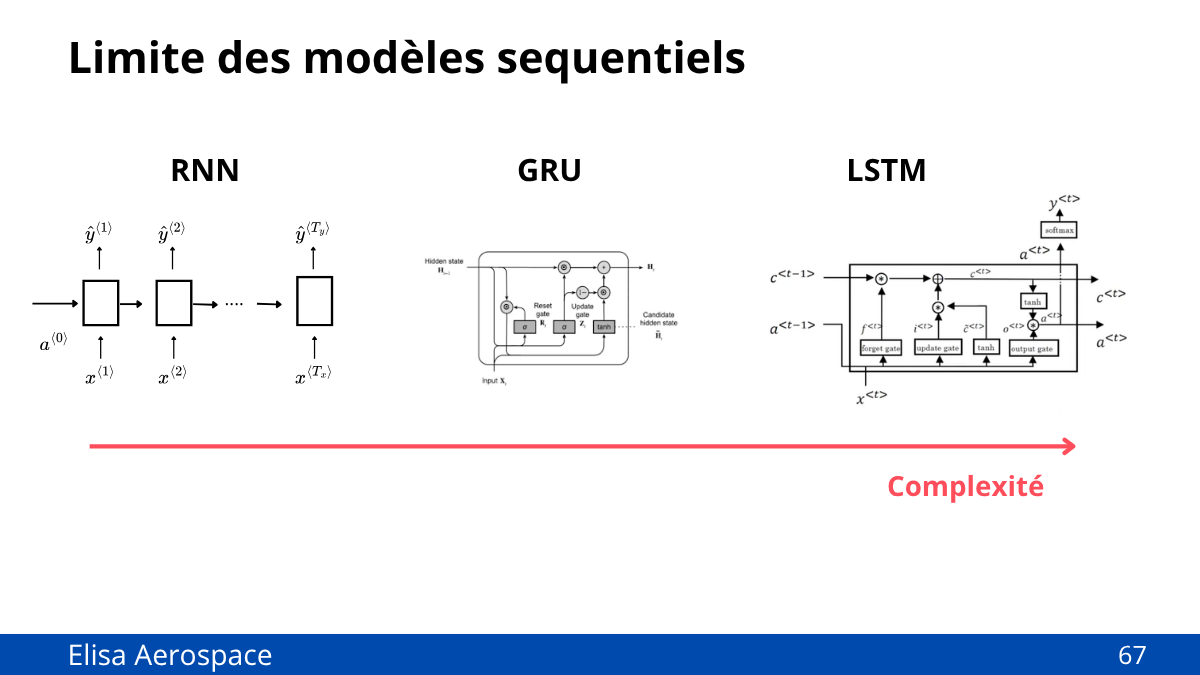</center>

---
### ✍️ Réponse R10

> En **10 lignes maximum** : qu'a appris un RNN sur ces trajectoires, et que n'a-t-il **pas** pu apprendre ? Chaque affirmation doit citer **une figure de votre notebook** (ex. « en 2.4, l'erreur ne baisse plus au-delà de 2 minutes d'historique »).

*Votre réponse ici (texte libre, citez vos figures).*

---
### ✍️ Réponse R11

> Slide 67 : dans ce TP, qu'est-ce qui était **lent** ou limité à cause de la récurrence ? (Pensez au décodeur de 4.1 et au temps des entraînements.) Que devrait changer le Transformer du prochain TP ?

*Votre réponse ici (texte libre, citez vos figures).*